In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.style
%matplotlib inline
from mlxtend.frequent_patterns import apriori,association_rules
from collections import Counter
from IPython.display import Image

from warnings import filterwarnings
filterwarnings("ignore")

In [2]:
files_path = "Groceries_dataset.csv(assignment 2).zip"

In [3]:
df = pd.read_csv(files_path, compression='zip', header=0, sep=',', quotechar='"')
df.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


In [4]:
df.tail()

,Member_number,Date,itemDescription
38760,4471,08-10-2014,sliced cheese
38761,2022,23-02-2014,candy
38762,1097,16-04-2014,cake bar
38763,1510,03-12-2014,fruit/vegetable juice
38764,1521,26-12-2014,cat food


In [5]:
df.describe()

,Member_number
count,38765.000000
mean,3003.641868
std,1153.611031
min,1000.000000
25%,2002.000000
50%,3005.000000
75%,4007.000000
max,5000.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 908.7 KB


In [7]:
df.isnull().sum()

Member_number      0
Date               0
itemDescription    0
dtype: int64

In [8]:
df = df.dropna(subset=['Member_number', 'Date','itemDescription'])

In [9]:
df['itemDescription'] = df['itemDescription'].str.lower()
df['itemDescription'] = df['itemDescription'].str.strip()

In [10]:
basket = df.groupby(['Member_number', 'Date'])['itemDescription'].apply(list).reset_index()
basket.head()

,Member_number,Date,itemDescription
0,1000,15-03-2015,"[sausage, whole milk, semi-finished bread, yog..."
1,1000,24-06-2014,"[whole milk, pastry, salty snack]"
2,1000,24-07-2015,"[canned beer, misc. beverages]"
3,1000,25-11-2015,"[sausage, hygiene articles]"
4,1000,27-05-2015,"[soda, pickled vegetables]"


In [11]:
from mlxtend.preprocessing import TransactionEncoder

transactions = basket['itemDescription'].tolist()

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)

df_encoded = pd.DataFrame(te_ary, columns=te.columns_)
df_encoded.head()

,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [12]:
df_encoded.info()
df_encoded.to_csv("Groceries_preprocessed.csv", index=False)

<class 'pandas.DataFrame'>
RangeIndex: 14963 entries, 0 to 14962
Columns: 167 entries, abrasive cleaner to zwieback
dtypes: bool(167)
memory usage: 2.4 MB


In [13]:
frequent_itemsets = apriori(df_encoded, min_support=0.001, use_colnames=True)

frequent_itemsets.head()

,support,itemsets
0,0.001470,frozenset({abrasive cleaner})
1,0.001938,frozenset({artif. sweetener})
2,0.008087,frozenset({baking powder})
3,0.001136,frozenset({bathroom cleaner})
4,0.033950,frozenset({beef})


In [14]:
frequent_itemsets.tail()

,support,itemsets
745,0.001136,"frozenset({sausage, whole milk, rolls/buns})"
746,0.001002,"frozenset({whole milk, soda, rolls/buns})"
747,0.001337,"frozenset({whole milk, yogurt, rolls/buns})"
748,0.001069,"frozenset({sausage, whole milk, soda})"
749,0.001470,"frozenset({sausage, whole milk, yogurt})"


In [15]:
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)
rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({beef}),frozenset({brown bread}),0.033950,0.037626,0.001537,0.045276,1.203301,1.0,2.597018e-04,1.008012,0.174891,0.021947,0.007949,0.043064
1,frozenset({brown bread}),frozenset({beef}),0.037626,0.033950,0.001537,0.040853,1.203301,1.0,2.597018e-04,1.007196,0.175559,0.021947,0.007145,0.043064
2,frozenset({beef}),frozenset({citrus fruit}),0.033950,0.053131,0.001804,0.053150,1.000349,1.0,6.297697e-07,1.000020,0.000361,0.021160,0.000020,0.043556
3,frozenset({citrus fruit}),frozenset({beef}),0.053131,0.033950,0.001804,0.033962,1.000349,1.0,6.297697e-07,1.000012,0.000369,0.021160,0.000012,0.043556
4,frozenset({beef}),frozenset({curd}),0.033950,0.033683,0.001270,0.037402,1.110396,1.0,1.262443e-04,1.003863,0.102915,0.019134,0.003848,0.037550


In [16]:
rules.tail()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
235,"frozenset({sausage, yogurt})",frozenset({whole milk}),0.005748,0.157923,0.00147,0.255814,1.619866,1.0,0.000563,1.131541,0.384877,0.009065,0.116250,0.132562
236,"frozenset({whole milk, yogurt})",frozenset({sausage}),0.011161,0.060349,0.00147,0.131737,2.182917,1.0,0.000797,1.082219,0.548014,0.020992,0.075973,0.078050
237,frozenset({sausage}),"frozenset({whole milk, yogurt})",0.060349,0.011161,0.00147,0.024363,2.182917,1.0,0.000797,1.013532,0.576701,0.020992,0.013351,0.078050
238,frozenset({whole milk}),"frozenset({sausage, yogurt})",0.157923,0.005748,0.00147,0.009310,1.619866,1.0,0.000563,1.003596,0.454430,0.009065,0.003583,0.132562
239,frozenset({yogurt}),"frozenset({sausage, whole milk})",0.085879,0.008955,0.00147,0.017121,1.911760,1.0,0.000701,1.008307,0.521727,0.015748,0.008239,0.090650


In [17]:
print("Number of frequent itemsets generated:", len(frequent_itemsets))
print("Number of association rules generated:", len(rules))

Number of frequent itemsets generated: 750
Number of association rules generated: 240


In [18]:
rules.sort_values(by='support', ascending=False).head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
196,frozenset({sausage}),frozenset({soda}),0.060349,0.097106,0.005948,0.098560,1.014975,1.0,8.775684e-05,1.001613,0.015702,0.039259,0.001611,0.079906
197,frozenset({soda}),frozenset({sausage}),0.097106,0.060349,0.005948,0.061253,1.014975,1.0,8.775684e-05,1.000963,0.016341,0.039259,0.000962,0.079906
198,frozenset({sausage}),frozenset({yogurt}),0.060349,0.085879,0.005748,0.095238,1.108986,1.0,5.648409e-04,1.010345,0.104587,0.040913,0.010239,0.081082
199,frozenset({yogurt}),frozenset({sausage}),0.085879,0.060349,0.005748,0.066926,1.108986,1.0,5.648409e-04,1.007049,0.107508,0.040913,0.007000,0.081082
126,frozenset({frankfurter}),frozenset({other vegetables}),0.037760,0.122101,0.005146,0.136283,1.116150,1.0,5.355097e-04,1.016420,0.108146,0.033261,0.016154,0.089214
127,frozenset({other vegetables}),frozenset({frankfurter}),0.122101,0.037760,0.005146,0.042146,1.116150,1.0,5.355097e-04,1.004579,0.118536,0.033261,0.004558,0.089214
86,frozenset({citrus fruit}),frozenset({yogurt}),0.053131,0.085879,0.004611,0.086792,1.010642,1.0,4.855926e-05,1.001001,0.011121,0.034311,0.001000,0.070244
87,frozenset({yogurt}),frozenset({citrus fruit}),0.085879,0.053131,0.004611,0.053696,1.010642,1.0,4.855926e-05,1.000598,0.011520,0.034311,0.000597,0.070244
137,frozenset({rolls/buns}),frozenset({fruit/vegetable juice}),0.110005,0.034017,0.003743,0.034022,1.000136,1.0,5.091755e-07,1.000005,0.000153,0.026679,0.000005,0.072021
136,frozenset({fruit/vegetable juice}),frozenset({rolls/buns}),0.034017,0.110005,0.003743,0.110020,1.000136,1.0,5.091755e-07,1.000017,0.000141,0.026679,0.000017,0.072021


In [19]:
rules.sort_values(by='confidence', ascending=False).head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
235,"frozenset({sausage, yogurt})",frozenset({whole milk}),0.005748,0.157923,0.001470,0.255814,1.619866,1.0,0.000563,1.131541,0.384877,0.009065,0.116250,0.132562
217,"frozenset({sausage, rolls/buns})",frozenset({whole milk}),0.005347,0.157923,0.001136,0.212500,1.345594,1.0,0.000292,1.069304,0.258214,0.007007,0.064813,0.109847
229,"frozenset({sausage, soda})",frozenset({whole milk}),0.005948,0.157923,0.001069,0.179775,1.138374,1.0,0.000130,1.026642,0.122281,0.006568,0.025951,0.093273
200,frozenset({semi-finished bread}),frozenset({whole milk}),0.009490,0.157923,0.001671,0.176056,1.114825,1.0,0.000172,1.022008,0.103985,0.010081,0.021534,0.093318
224,"frozenset({yogurt, rolls/buns})",frozenset({whole milk}),0.007819,0.157923,0.001337,0.170940,1.082428,1.0,0.000102,1.015701,0.076751,0.008130,0.015459,0.089702
234,"frozenset({sausage, whole milk})",frozenset({yogurt}),0.008955,0.085879,0.001470,0.164179,1.911760,1.0,0.000701,1.093681,0.481231,0.015748,0.085657,0.090650
111,frozenset({detergent}),frozenset({whole milk}),0.008621,0.157923,0.001403,0.162791,1.030824,1.0,0.000042,1.005814,0.030162,0.008499,0.005781,0.085839
145,frozenset({ham}),frozenset({whole milk}),0.017109,0.157923,0.002740,0.160156,1.014142,1.0,0.000038,1.002659,0.014188,0.015904,0.002652,0.088754
178,frozenset({processed cheese}),frozenset({rolls/buns}),0.010158,0.110005,0.001470,0.144737,1.315734,1.0,0.000353,1.040610,0.242430,0.012387,0.039025,0.079051
174,frozenset({packaged fruit/vegetables}),frozenset({rolls/buns}),0.008488,0.110005,0.001203,0.141732,1.288421,1.0,0.000269,1.036967,0.225772,0.010256,0.035649,0.076334


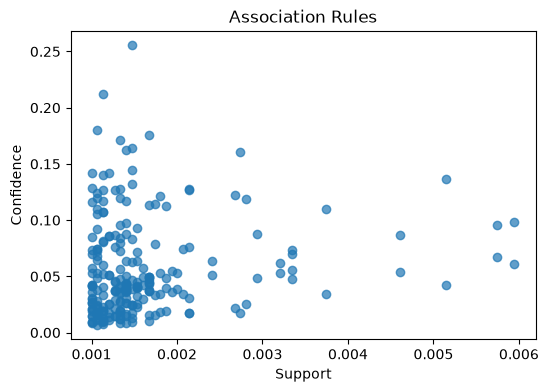

In [20]:
plt.figure(figsize=(6,4))
plt.scatter(rules['support'], rules['confidence'], alpha=0.7)
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Association Rules')
plt.show()


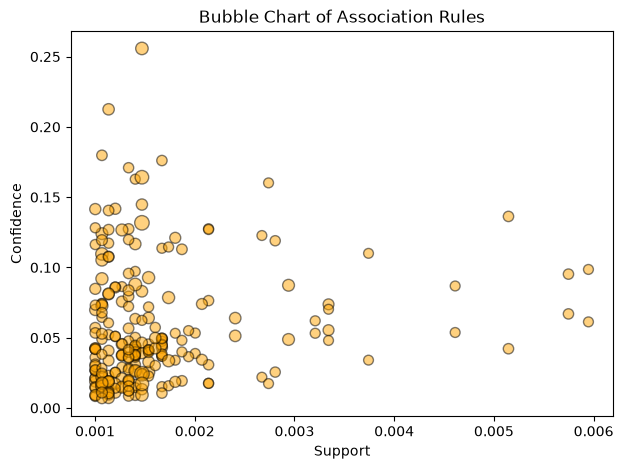

In [21]:
plt.figure(figsize=(7,5))
plt.scatter(rules['support'], rules['confidence'], 
            s=rules['lift']*50, alpha=0.5, c='orange', edgecolor='k')
plt.title('Bubble Chart of Association Rules')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.show()


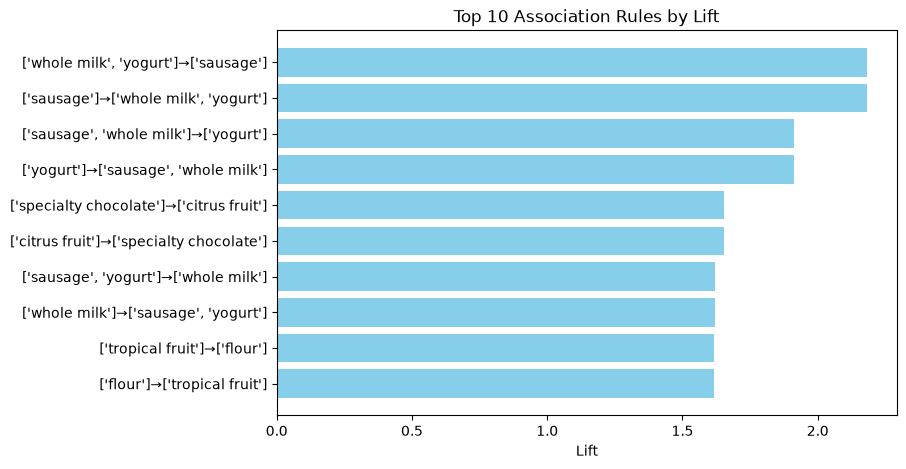

In [22]:
top10 = rules.sort_values('lift', ascending=False).head(10)
plt.figure(figsize=(8,5))
plt.barh(range(len(top10)), top10['lift'], color='skyblue')
plt.yticks(range(len(top10)), [f"{list(a)}→{list(c)}" 
         for a,c in zip(top10['antecedents'], top10['consequents'])])
plt.xlabel('Lift')
plt.title('Top 10 Association Rules by Lift')
plt.gca().invert_yaxis()
plt.show()


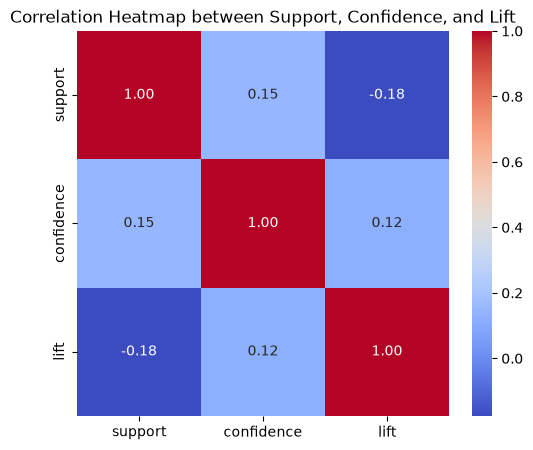

In [23]:
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(rules[['support','confidence','lift']].corr(), 
            annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap between Support, Confidence, and Lift')
plt.show()


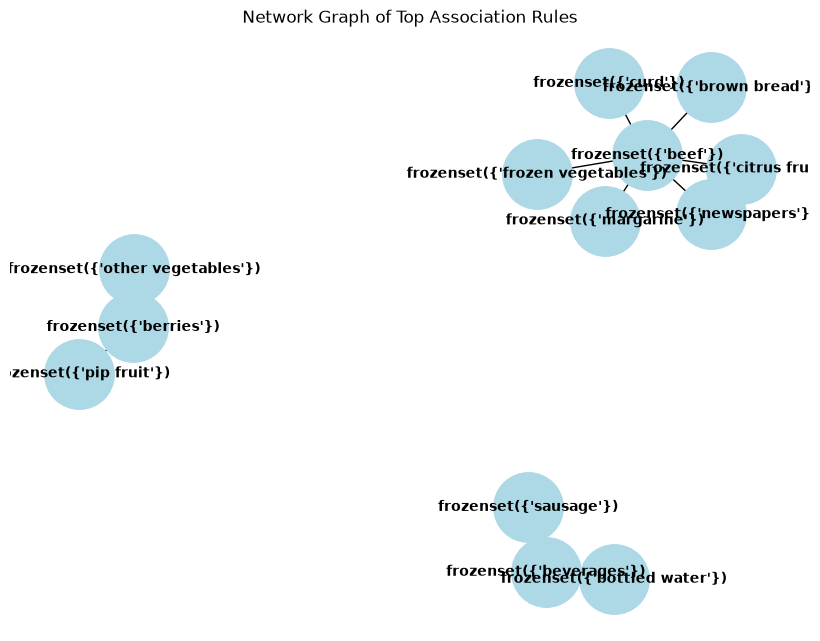

In [24]:
import networkx as nx

G = nx.from_pandas_edgelist(rules.head(20), 
                            source='antecedents', 
                            target='consequents', 
                            edge_attr=True)

plt.figure(figsize=(8,6))
pos = nx.spring_layout(G, k=0.5)
nx.draw(G, pos, with_labels=True, node_size=2500, 
        node_color='lightblue', font_size=10, font_weight='bold')
plt.title('Network Graph of Top Association Rules')
plt.show()


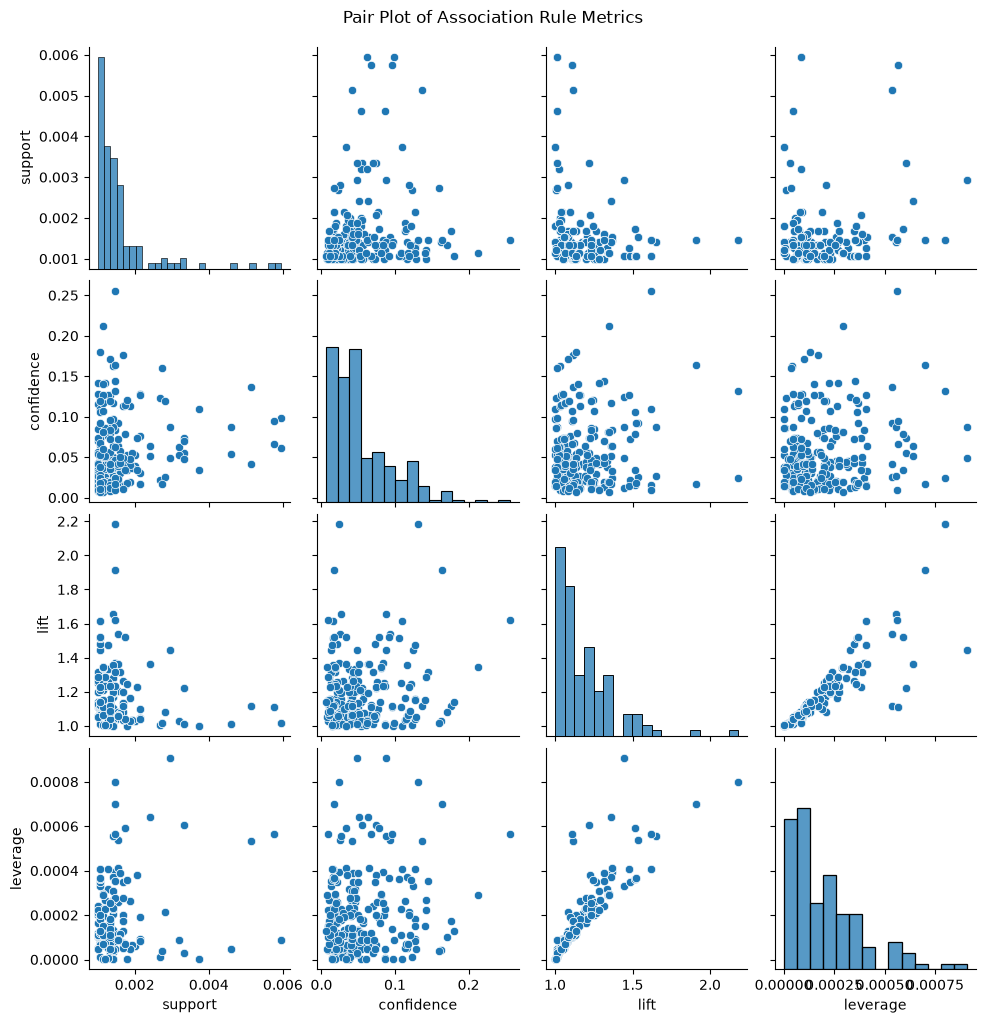

In [25]:
sns.pairplot(rules[['support','confidence','lift','leverage']])
plt.suptitle('Pair Plot of Association Rule Metrics', y=1.02)
plt.show()


In [26]:
from mlxtend.frequent_patterns import fpgrowth, association_rules

frequent_itemsets_fp = fpgrowth(df_encoded, min_support=0.002, use_colnames=True)
frequent_itemsets_fp.sort_values(by='support', ascending=False).head(10)


,support,itemsets
0,0.157923,frozenset({whole milk})
17,0.122101,frozenset({other vegetables})
13,0.110005,frozenset({rolls/buns})
9,0.097106,frozenset({soda})
1,0.085879,frozenset({yogurt})
24,0.069572,frozenset({root vegetables})
20,0.067767,frozenset({tropical fruit})
37,0.060683,frozenset({bottled water})
2,0.060349,frozenset({sausage})
62,0.053131,frozenset({citrus fruit})


In [27]:
rules_fp = association_rules(frequent_itemsets_fp, metric="lift", min_threshold=1)
rules_fp[['antecedents','consequents','support','confidence','lift']].head(10)


,antecedents,consequents,support,confidence,lift
0,frozenset({sausage}),frozenset({yogurt}),0.005748,0.095238,1.108986
1,frozenset({yogurt}),frozenset({sausage}),0.005748,0.066926,1.108986
2,frozenset({sausage}),frozenset({soda}),0.005948,0.098560,1.014975
3,frozenset({soda}),frozenset({sausage}),0.005948,0.061253,1.014975
4,frozenset({sausage}),frozenset({pastry}),0.003208,0.053156,1.027617
5,frozenset({pastry}),frozenset({sausage}),0.003208,0.062016,1.027617
6,frozenset({frankfurter}),frozenset({other vegetables}),0.005146,0.136283,1.116150
7,frozenset({other vegetables}),frozenset({frankfurter}),0.005146,0.042146,1.116150
8,frozenset({sausage}),frozenset({curd}),0.002941,0.048726,1.446615
9,frozenset({curd}),frozenset({sausage}),0.002941,0.087302,1.446615


In [28]:
rules_fp.sort_values('lift', ascending=False).head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
9,frozenset({curd}),frozenset({sausage}),0.033683,0.060349,0.002941,0.087302,1.446615,1.0,0.000908,1.029531,0.319493,0.032282,0.028684,0.068014
8,frozenset({sausage}),frozenset({curd}),0.060349,0.033683,0.002941,0.048726,1.446615,1.0,0.000908,1.015814,0.328559,0.032282,0.015568,0.068014
27,frozenset({brown bread}),frozenset({canned beer}),0.037626,0.046916,0.002406,0.063943,1.362937,1.0,0.000641,1.018191,0.276701,0.029292,0.017866,0.057613
26,frozenset({canned beer}),frozenset({brown bread}),0.046916,0.037626,0.002406,0.051282,1.362937,1.0,0.000641,1.014394,0.279398,0.029292,0.014190,0.057613
11,frozenset({frozen vegetables}),frozenset({sausage}),0.028002,0.060349,0.002072,0.073986,1.225966,1.0,0.000382,1.014726,0.189627,0.024012,0.014513,0.054158
10,frozenset({sausage}),frozenset({frozen vegetables}),0.060349,0.028002,0.002072,0.034330,1.225966,1.0,0.000382,1.006553,0.196155,0.024012,0.006510,0.054158
21,frozenset({bottled beer}),frozenset({sausage}),0.045312,0.060349,0.003342,0.073746,1.222000,1.0,0.000607,1.014464,0.190292,0.032658,0.014258,0.064559
20,frozenset({sausage}),frozenset({bottled beer}),0.060349,0.045312,0.003342,0.055371,1.222000,1.0,0.000607,1.010649,0.193337,0.032658,0.010537,0.064559
6,frozenset({frankfurter}),frozenset({other vegetables}),0.037760,0.122101,0.005146,0.136283,1.116150,1.0,0.000536,1.016420,0.108146,0.033261,0.016154,0.089214
7,frozenset({other vegetables}),frozenset({frankfurter}),0.122101,0.037760,0.005146,0.042146,1.116150,1.0,0.000536,1.004579,0.118536,0.033261,0.004558,0.089214
